# Laptop Data Exploration

## Business Question
What factors influence laptop prices in the global market?

## Objective
The objective of this notebook is to explore the cleaned laptop dataset, identify patterns and relationships between laptop specifications and prices, and determine which features may be useful for predicting laptop prices.

## Approach
1. **Univariate Analysis:** Examine the distribution of individual variables.
2. **Bivariate Analysis:** Investigate relationships between laptop prices and individual features.
3. **Multivariate Analysis:** Explore how multiple laptop specifications relate to price.


In [46]:
# import necessary dependancies
import pandas as pd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
#get data
file_path="../data/global-laptop-selling-dataset/clean_global_laptop_selling_data.csv"
laptop_df=pd.read_csv(file_path,index_col="laptop_ID")

In [48]:
# display 5 first rows
laptop_df.head()

,Company,Product,TypeName,Inches,Ram,OpSys,Price_euros,ResolutionWidth,ResolutionHeight,DisplayFeatures,...,CpuModel,ClockSpeed,SSDCapacityGB,HDDCapacityGB,FlashStorageGB,HybridStorageGB,WeightKg,GpuBrand,GpuModel,OsFamily
laptop_ID,,,,,,,,,,,,,,,,,,,,,
1,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1339.69,2560,1600,IPS Panel Retina Display,...,Core i5,2.3,128.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 640,macOS
2,Apple,Macbook Air,Ultrabook,13.3,8,macOS,898.94,1440,900,NaN,...,Core i5,1.8,0.0,0.0,128.0,0.0,1.34,Intel,HD Graphics 6000,macOS
3,HP,250 G6,Notebook,15.6,8,No OS,575.00,1920,1080,Full HD,...,Core i5 7200U,2.5,256.0,0.0,0.0,0.0,1.86,Intel,HD Graphics 620,No OS
4,Apple,MacBook Pro,Ultrabook,15.4,16,macOS,2537.45,2880,1800,IPS Panel Retina Display,...,Core i7,2.7,512.0,0.0,0.0,0.0,1.83,AMD,Radeon Pro 455,macOS
5,Apple,MacBook Pro,Ultrabook,13.3,8,macOS,1803.60,2560,1600,IPS Panel Retina Display,...,Core i5,3.1,256.0,0.0,0.0,0.0,1.37,Intel,Iris Plus Graphics 650,macOS


In [49]:
# get summary of the data
laptop_df.info()

<class 'pandas.DataFrame'>
Index: 1303 entries, 1 to 1320
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Company           1303 non-null   str    
 1   Product           1303 non-null   str    
 2   TypeName          1303 non-null   str    
 3   Inches            1303 non-null   float64
 4   Ram               1303 non-null   int64  
 5   OpSys             1303 non-null   str    
 6   Price_euros       1303 non-null   float64
 7   ResolutionWidth   1303 non-null   int64  
 8   ResolutionHeight  1303 non-null   int64  
 9   DisplayFeatures   989 non-null    str    
 10  CpuBrand          1303 non-null   str    
 11  CpuModel          1303 non-null   str    
 12  ClockSpeed        1303 non-null   float64
 13  SSDCapacityGB     1303 non-null   float64
 14  HDDCapacityGB     1303 non-null   float64
 15  FlashStorageGB    1303 non-null   float64
 16  HybridStorageGB   1303 non-null   float64
 17  WeightKg   

In [50]:
# statistical summary of data
laptop_df.describe()

,Inches,Ram,Price_euros,ResolutionWidth,ResolutionHeight,ClockSpeed,SSDCapacityGB,HDDCapacityGB,FlashStorageGB,HybridStorageGB,WeightKg
count,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000,1303.000000
mean,15.017191,8.382195,1123.686992,1894.784344,1070.830391,2.298772,184.027629,422.477360,4.555641,9.034536,2.038734
std,1.426304,5.084665,699.009043,494.641028,284.519410,0.506340,188.268689,528.006298,30.274090,94.738890,0.665475
min,10.100000,2.000000,174.000000,1366.000000,768.000000,0.900000,0.000000,0.000000,0.000000,0.000000,0.690000
25%,14.000000,4.000000,599.000000,1600.000000,900.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.500000
50%,15.600000,8.000000,977.000000,1920.000000,1080.000000,2.500000,256.000000,0.000000,0.000000,0.000000,2.040000
75%,15.600000,8.000000,1487.880000,1920.000000,1080.000000,2.700000,256.000000,1024.000000,0.000000,0.000000,2.300000
max,18.400000,64.000000,6099.000000,3840.000000,2160.000000,3.600000,1024.000000,2048.000000,512.000000,1024.000000,4.700000


## Univariate analysis

#### Distribution of Laptops by Company

This analysis examines the number of laptops produced by each company in the dataset. The goal is to identify which companies are most represented and which have the fewest laptops in the dataset.

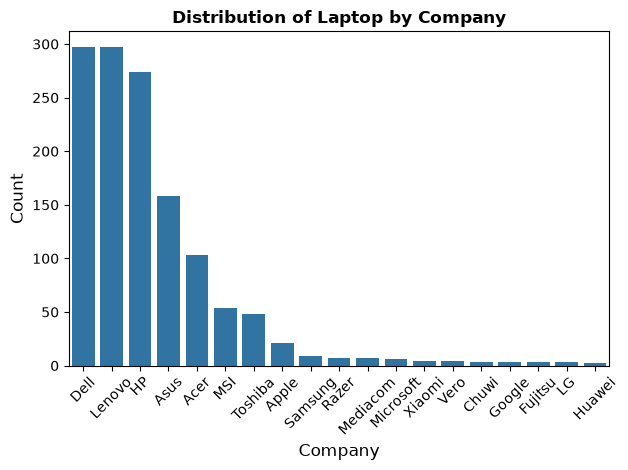

In [51]:
fig,ax=plt.subplots()
company_order=laptop_df["Company"].value_counts().index

sns.countplot(data=laptop_df,x="Company",order=company_order ,ax=ax)
ax.set_xlabel("Company",fontsize=12)
ax.set_ylabel("Count",fontsize=12)
ax.set_title("Distribution of Laptop by Company",fontsize=12,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation:** Lenovo and Dell have the highest number of laptops in the dataset, while Huawei has the lowest representation.

### Distribution of Laptops by Type

This analysis examines the number of laptops in each product type to identify which types are most represented and which have the fewest entries in the dataset.


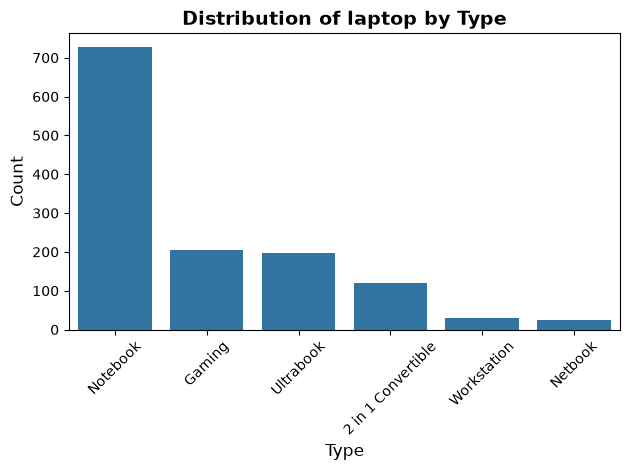

In [52]:
fig,ax=plt.subplots()
type_order =laptop_df["TypeName"].value_counts().index
sns.countplot(data=laptop_df,x="TypeName",order=type_order,ax=ax)
ax.set_ylabel("Count",fontsize=12)
ax.set_xlabel("Type",fontsize=12)
ax.set_title("Distribution of laptop by Type",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()


**Observation:** Notebook is the most common laptop type in the dataset, while Netbook is the least common.

#### Distribution of laptops by inches
This analysis examine the distribution of laptops by inches

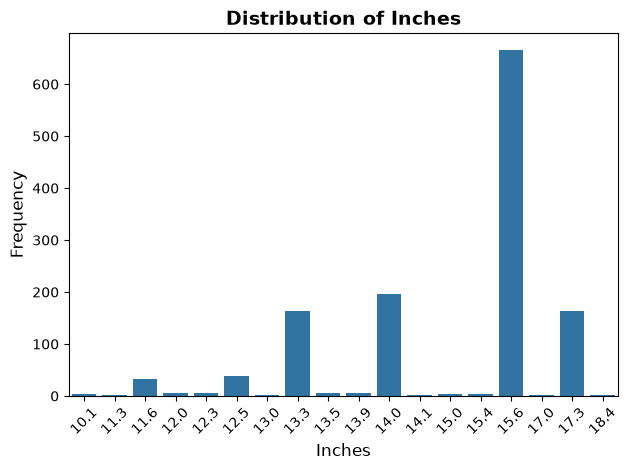

In [53]:
fig,ax=plt.subplots()
sns.countplot(data=laptop_df,x="Inches",ax=ax)
ax.set_xlabel("Inches",fontsize=12)
ax.set_ylabel("Frequency",fontsize=12)
ax.set_title("Distribution of Inches",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Distribution of laptop by RAM
This analysis examine distribution of laptop by ram to indentify which ram is most common and which is least common

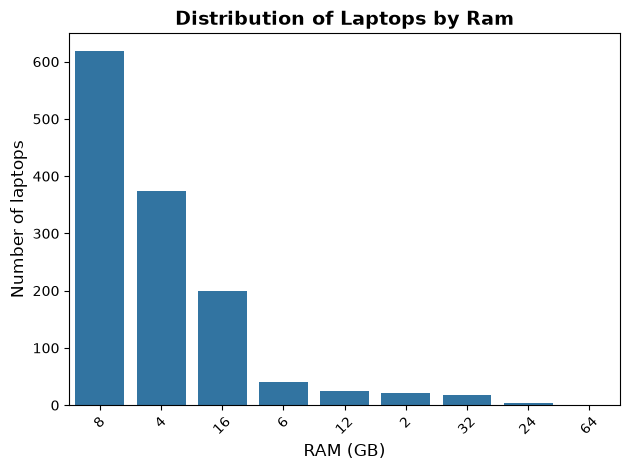

In [54]:
fig,ax=plt.subplots()
ram_order=laptop_df["Ram"].value_counts().index
sns.countplot(data=laptop_df,x="Ram",order=ram_order,ax=ax)
ax.set_xlabel("RAM (GB)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Ram",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observation** 8GB RAM is the most common followed by 4 while 64GB RAM is least common followed by 24GB

#### Distribution of laptops by operating system
This analysis examine the distribution of laptops by operating system to find which is the most common operating system and which is the least

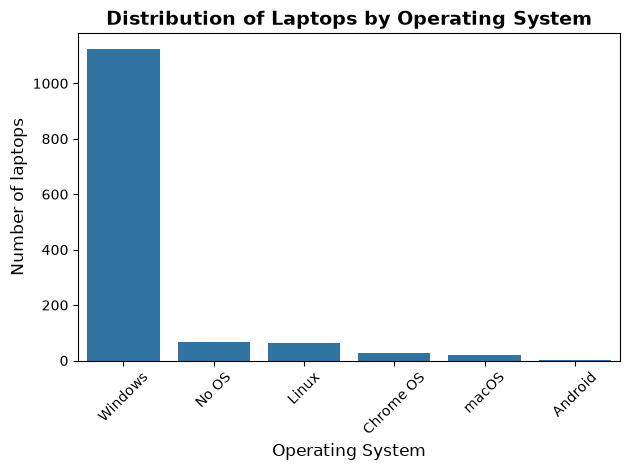

In [57]:
fig,ax=plt.subplots()
os_order=laptop_df["OsFamily"].value_counts().index
sns.countplot(data=laptop_df,x="OsFamily",order=os_order,ax=ax)
ax.set_xlabel("Operating System",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops by Operating System",fontsize=14,fontweight="bold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [58]:
laptop_df["OsFamily"].value_counts()

OsFamily
Windows      1125
No OS          66
Linux          62
Chrome OS      27
macOS          21
Android         2
Name: count, dtype: int64

**Observation** Windows is the most common operating system with 1125 laptops  while Android is the least common with 2 laptops

#### Distribution of Laptop price
This analysis examines the distribution of laptop price

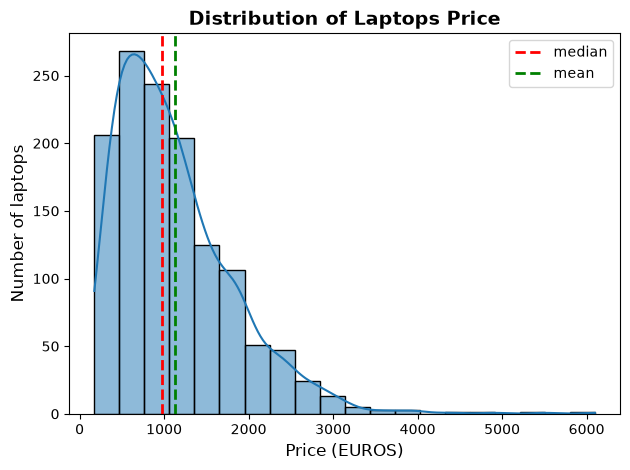

In [76]:
fig,ax=plt.subplots()
sns.histplot(data=laptop_df,x="Price_euros",bins=20,kde=True,ax=ax)
median=laptop_df["Price_euros"].median()
mean=laptop_df["Price_euros"].mean()
ax.axvline(median,color="red",linestyle="--",linewidth=2,label="median")
ax.axvline(mean,color="green",linestyle="--",linewidth=2,label="mean")
ax.set_xlabel("Price (EUROS)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops Price",fontsize=14,fontweight="bold")
ax.legend()

plt.tight_layout()
plt.show()

**Observation** 
- Laptop price is right skewed with median less than mean
- Typical laptop price is around 1000 but there are outliers with laptops up to 6000

#### Distribution of Weight by Laptops
This examine the distribution of laptops weight

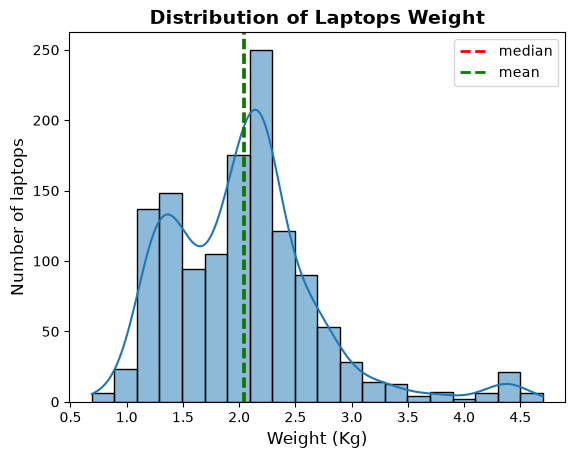

In [74]:
fig,ax=plt.subplots()
sns.histplot(data=laptop_df,x="WeightKg",bins=20,kde=True,ax=ax)
median=laptop_df["WeightKg"].median()
mean=laptop_df["WeightKg"].mean()
ax.axvline(median,color="red",linestyle="--",linewidth=2,label="median")
ax.axvline(mean,color="green",linestyle="--",linewidth=2,label="mean")
ax.set_xlabel("Weight (Kg)",fontsize=12)
ax.set_ylabel("Number of laptops",fontsize=12)
ax.set_title("Distribution of Laptops Weight",fontsize=14,fontweight="bold")
ax.legend()

In [75]:
laptop_df["WeightKg"].describe()

count    1303.000000
mean        2.038734
std         0.665475
min         0.690000
25%         1.500000
50%         2.040000
75%         2.300000
max         4.700000
Name: WeightKg, dtype: float64

**Observation**
- Laptop weight is bimodal  with one peak around 1.2 to 1.4kg and larger one around 2.0 to 2.3kg
- The mean and median overlap with mean of 2.04 and median of 2.04 so the distribution is roughly balanced rather than strong skewed
- Most laptop weight between 1.0 and 3.0kg

#### Distribution of Laptop Storage

In [ ]:
storage_cols= [
"SSDCapacityGB"    
"HDDCapacityGB"     
"FlashStorageGB"   
"HybridStorageGB"  ] 